In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
print("Libraries imported successfully!")

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_excel('Linear_Regression_FDP_Student_Dataset.xlsx')

print("Dataset loaded successfully!")

In [ ]:
# Display first five rows
print("First five rows:")
display(df.head())

# Display last five rows
print("Last five rows:")
display(df.tail())

# Display random five rows
print("Random five rows:")
display(df.sample(5))

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("Column names:")
print(df.columns)

# Dataset information
print("Dataset information:")
df.info()

# Statistical summary
print("Statistical summary:")
display(df.describe())

First five rows:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
0,1001,1.0,65,38,40,35
1,1002,2.0,70,42,45,40
2,1003,3.0,72,48,50,46
3,1004,4.0,75,50,55,52
4,1005,5.0,78,55,58,57


Last five rows:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
25,1026,8.0,88,69,73,76
26,1027,9.0,91,74,79,83
27,1028,3.5,75,50,53,51
28,1029,6.5,87,66,68,69
29,1030,8.5,90,71,76,79


Random five rows:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
1,1002,2.0,70,42,45,40
7,1008,8.0,85,68,72,73
18,1019,9.5,93,75,80,85
2,1003,3.0,72,48,50,46
8,1009,9.0,88,72,78,80


Dataset shape: (30, 6)
Column names:
Index(['Student_ID', 'Study_Hours', 'Attendance_Percent', 'Previous_Marks',
       'Assignment_Score', 'Exam_Marks'],
      dtype='object')
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_ID          30 non-null     int64  
 1   Study_Hours         30 non-null     float64
 2   Attendance_Percent  30 non-null     int64  
 3   Previous_Marks      30 non-null     int64  
 4   Assignment_Score    30 non-null     int64  
 5   Exam_Marks          30 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 1.5 KB
Statistical summary:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,1015.500000,5.566667,80.666667,57.933333,61.800000,61.333333
std,8.803408,2.615383,7.778544,11.343944,12.338334,15.173328
min,1001.000000,1.000000,65.000000,38.000000,40.000000,35.000000
25%,1008.250000,3.500000,75.000000,49.250000,52.250000,49.500000
50%,1015.500000,5.750000,80.500000,57.500000,61.000000,61.000000
75%,1022.750000,7.875000,86.750000,67.500000,71.500000,72.500000
max,1030.000000,10.000000,95.000000,78.000000,85.000000,90.000000


In [ ]:
# Average exam marks
print("Average exam marks:")
print(df['Exam_Marks'].mean())

# Maximum exam marks
print("Maximum exam marks:")
print(df['Exam_Marks'].max())

# Minimum exam marks
print("Minimum exam marks:")
print(df['Exam_Marks'].min())

# Students scoring above 70
print("Students scoring above 70:")
display(df[df['Exam_Marks'] > 70])

# Students with attendance above 80
print("Attendance above 80:")
display(df[df['Attendance_Percent'] > 80])

# Sort students by marks
print("Students sorted by exam marks:")
display(df.sort_values(by='Exam_Marks', ascending=False))

# Average marks by attendance is not a group category,
# so let's create attendance groups.
df['Attendance_Group'] = pd.cut(
    df['Attendance_Percent'],
    bins=[0, 70, 80, 90, 100],
    labels=['Low', 'Moderate', 'Good', 'Excellent']
)

print("Average marks by attendance group:")
display(df.groupby('Attendance_Group', observed=False)['Exam_Marks'].mean())

Average exam marks:
61.333333333333336
Maximum exam marks:
90
Minimum exam marks:
35
Students scoring above 70:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
7,1008,8.0,85,68,72,73
8,1009,9.0,88,72,78,80
9,1010,10.0,95,78,85,90
16,1017,7.5,86,65,70,71
17,1018,8.5,89,70,75,77
18,1019,9.5,93,75,80,85
25,1026,8.0,88,69,73,76
26,1027,9.0,91,74,79,83
29,1030,8.5,90,71,76,79


Attendance above 80:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
6,1007,7.0,82,62,68,68
7,1008,8.0,85,68,72,73
8,1009,9.0,88,72,78,80
9,1010,10.0,95,78,85,90
14,1015,5.5,81,57,60,60
15,1016,6.5,84,61,65,65
16,1017,7.5,86,65,70,71
17,1018,8.5,89,70,75,77
18,1019,9.5,93,75,80,85
23,1024,6.0,83,60,64,64


Students sorted by exam marks:


,Student_ID,Study_Hours,Attendance_Percent,Previous_Marks,Assignment_Score,Exam_Marks
9,1010,10.0,95,78,85,90
18,1019,9.5,93,75,80,85
26,1027,9.0,91,74,79,83
8,1009,9.0,88,72,78,80
29,1030,8.5,90,71,76,79
17,1018,8.5,89,70,75,77
25,1026,8.0,88,69,73,76
7,1008,8.0,85,68,72,73
16,1017,7.5,86,65,70,71
24,1025,7.0,85,64,69,70


Average marks by attendance group:


,Exam_Marks
Attendance_Group,
Low,37.666667
Moderate,51.416667
Good,71.000000
Excellent,86.000000


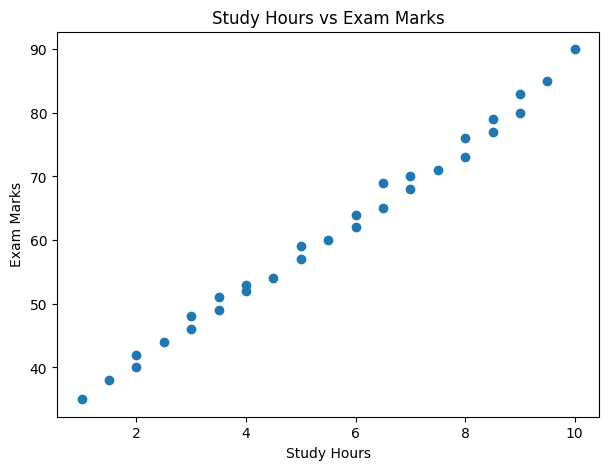

In [ ]:
#scatter plot
plt.figure(figsize=(7, 5))

plt.scatter(df['Study_Hours'], df['Exam_Marks'])

plt.xlabel('Study Hours')
plt.ylabel('Exam Marks')
plt.title('Study Hours vs Exam Marks')

plt.show()

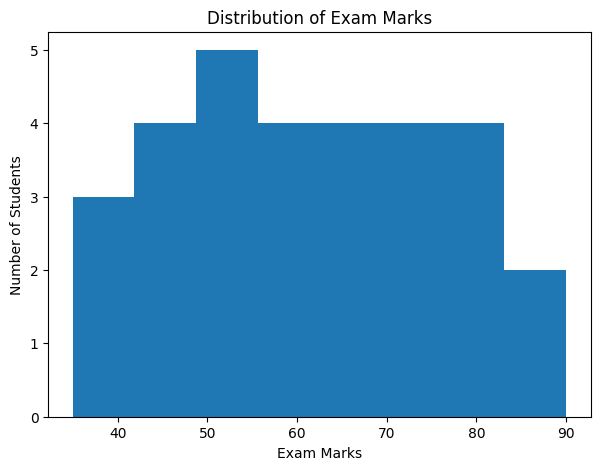

In [ ]:
#histogram
plt.figure(figsize=(7, 5))

plt.hist(df['Exam_Marks'], bins=8)

plt.xlabel('Exam Marks')
plt.ylabel('Number of Students')
plt.title('Distribution of Exam Marks')

plt.show()

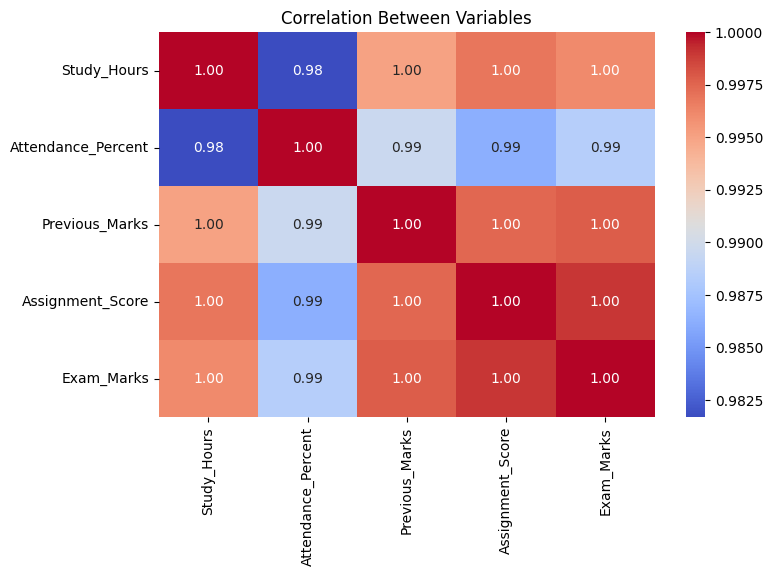

In [ ]:
#correlation heatmap
plt.figure(figsize=(8, 5))

correlation = df[
    ['Study_Hours', 'Attendance_Percent',
     'Previous_Marks', 'Assignment_Score', 'Exam_Marks']
].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Between Variables')

plt.show()

In [ ]:
#simple linear regression
#defining x and y
X = df[['Study_Hours']]

y = df['Exam_Marks']

print("Independent variable:")
display(X.head())

print("Dependent variable:")
display(y.head())

Independent variable:


,Study_Hours
0,1.0
1,2.0
2,3.0
3,4.0
4,5.0


Dependent variable:


,Exam_Marks
0,35
1,40
2,46
3,52
4,57


In [ ]:
#split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 1)
Testing data: (6, 1)


In [ ]:
#create and train the model
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
#find slope and intercept
print("Slope:", model.coef_[0])

print("Intercept:", model.intercept_)

Slope: 5.771412563905035
Intercept: 29.176272848238675


,Actual Marks,Predicted Marks
0,51,49.376217
1,65,66.690455
2,64,63.804748
3,77,78.233280
4,80,81.118986
5,90,86.890398


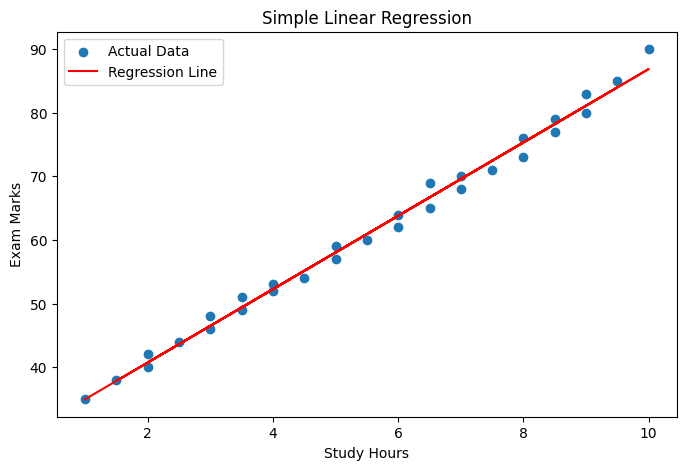

In [ ]:
#predictions and visualise the regression line
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred
})

display(results)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label='Actual Data')

plt.plot(
    X,
    model.predict(X),
    color='red',
    label='Regression Line'
)

plt.xlabel('Study Hours')
plt.ylabel('Exam Marks')

plt.title('Simple Linear Regression')

plt.legend()

plt.show()